# E242 Stage A · Calibrating a health reward for continual MAE

**Complete on edgelab · 5 seeds × 24 development clips × 2 mask draws · 3,360 action outcomes**

The development data locked **incoming at 0.125× LR** as the +1 fixed comparator and **skip** as the +16 fixed comparator. Incoming at 0.125× gained just **+0.018 percentage points** at +1. Every trainable action had a negative mean change at +16, although several intervals included zero.

The development-only +16 semantic oracle gained **+0.430 pp** over skip when a different mask draw scored its action. The realized health reward gained **−0.103 pp** under the same cross-draw check. This is an early indication of action opportunity and weak reward alignment. The held-out Stage B analysis determines whether those patterns replicate and whether any controller is warranted.

## What Stage A measured

Development captures occupy registered slots in the archived 18-regime Phase 1.2.5 correlated BDD100K walk. At each slot, the learner sees 16 consecutive native frames before branching. Every action restores the same MAE, AdamW, observation history and random state. Each of two paired mask draws tests every action at both horizons. +1 and +16 refer to **incoming frames**, with at most one optimizer update per arrival. The model is TinyMAE at 64 px, with a batch of four and a past-only 128-image reservoir.

Each branch is scored on fixed 256-capture new and historical banks for unlabeled health, and on independent annotated images for downstream quality. The downstream aggregate is 60% new and 40% historical, with scene, weather, traffic light and pedestrian equally weighted within each side. Lighting is recorded separately. Stage A uses labels to choose a fixed comparison action for each horizon. The health reward uses unlabeled measurements.

| Action | Learning strategy |
| --- | --- |
| A0 | Skip all updates and observe the incoming frames |
| A1, A2, A3 | Incoming learning at 0.125×, 0.5× or 1× the base LR |
| A4, A5 | Replace 25% or 50% of each batch with historical replay, at 0.5× LR |
| A6 | At +16, eight incoming updates followed by eight all-replay updates, at 0.5× LR |
| A7 | At +16, alternate incoming and all-replay blocks of four, at 0.5× LR |

In [1]:
from base64 import b64decode
from html import escape
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from IPython.display import HTML, display

actions = ('Skip', 'Incoming 0.125×', 'Incoming 0.5×', 'Incoming 1×', '25% replay', '50% replay', '8 incoming, then 8 replay', 'Alternate 4 incoming and 4 replay')
metrics = ('New loss', 'New retrieval margin', 'Historical loss', 'Historical retrieval margin')
variants = ('loss only', 'retrieval only', 'combined', 'spectral + CKA', 'full reward')
calibration = {'scales': {'1': [0.002417798734183058, 0.0004489424639475671, 0.0025718972976339098, 0.0004057943508760184], '16': [0.03534070017435048, 0.0045706297235831314, 0.03781625389319525, 0.004250369816568706]}, 'fixed': {'1': 1, '16': 0}, 'threshold_pp': 0.25}
archive_sha256 = 'dfef04d4f046d1f646d8311ae237e6a408a57174c627e47f9a35afecc81d75b0'
payload = (
    '...'
)
with np.load(BytesIO(b64decode(payload)), allow_pickle=False) as embedded:
    arrays = {name: embedded[name] for name in embedded.files}

def table(columns, rows):
    format_row = lambda tag, entries: '<tr>' + ''.join(
        f'<{tag}>{escape(str(item))}</{tag}>' for item in entries
    ) + '</tr>'
    return HTML('<table><thead>' + format_row('th', columns) + '</thead><tbody>' + ''.join(
        format_row('td', row) for row in rows
    ) + '</tbody></table>')

rng = np.random.default_rng(242400)
seed_sample = rng.integers(5, size=(8000, 5))
clip_sample = rng.integers(24, size=(8000, 24))

def estimate(values):
    """Average paired draws first, then resample seed and clip axes independently."""
    per_state = values.mean(axis=2)
    sampled = per_state[seed_sample[:, :, None], clip_sample[:, None, :]].mean(axis=(1, 2))
    return per_state.mean(axis=(0, 1)), np.percentile(sampled, [2.5, 97.5], axis=0)

def interval(values):
    point, (lo, hi) = estimate(values)
    return f'{point:+.3f} [{lo:+.3f}, {hi:+.3f}]'

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

## Fixed comparators chosen on development clips

Each point is the mean change from the common pre-action checkpoint. Intervals resample seeds and captures, keeping the two mask draws paired within each cell. They condition on the external probe corpus. Blue and green markers split the aggregate into new and historical quality.

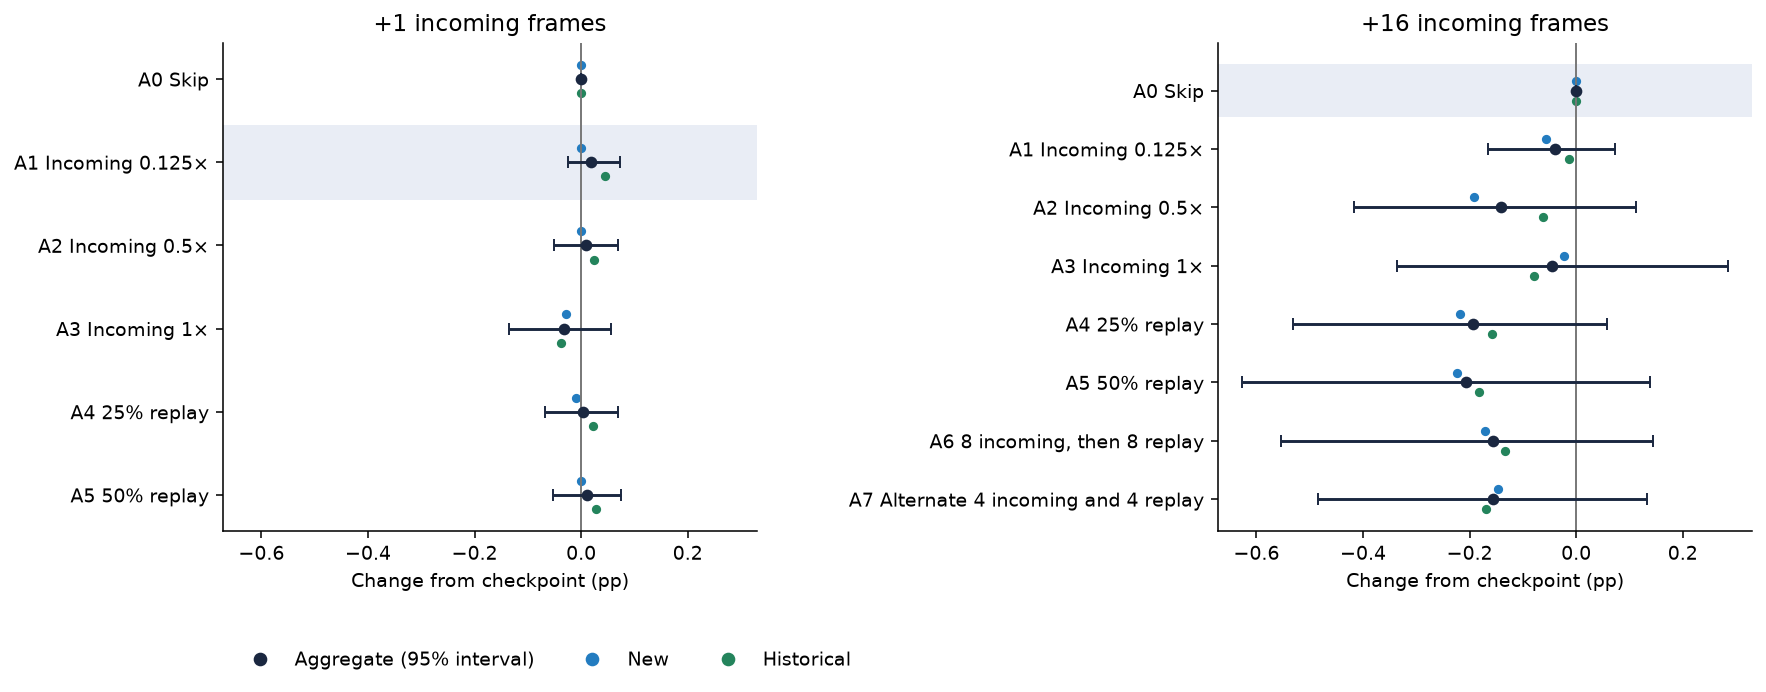

Horizon,Locked fixed action,"Development change (pp, 95% interval)"
+1,A1 Incoming 0.125×,"+0.018 [-0.025, +0.074]"
+16,A0 Skip,"+0.000 [+0.000, +0.000]"


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharex=True, layout='constrained')
fixed_rows = []
for h, ax in zip((1, 16), axes):
    quality = arrays[f'quality{h}']
    n = quality.shape[-2]
    label = calibration['fixed'][str(h)]
    point, (lo, hi) = estimate(quality[..., 0])
    selected = np.arange(n)
    ax.axhspan(label - .44, label + .44, color='#e9edf5', zorder=0)
    ax.axvline(0, color='#777', lw=1)
    ax.errorbar(point, selected, xerr=(point-lo, hi-point), fmt='o', color='#1a2740', capsize=3, ms=5)
    for j, color, offset in [(1, '#237cc0', -.17), (2, '#24845c', .17)]:
        ax.scatter(quality[..., j].mean((0, 1, 2)), selected + offset, color=color, s=14)
    ax.set_yticks(selected, [f'A{i} {name}' for i, name in enumerate(actions[:n])])
    ax.invert_yaxis()
    ax.set(title=f'+{h} incoming frames', xlabel='Change from checkpoint (pp)')
    fixed_rows.append((f'+{h}', f'A{label} {actions[label]}', interval(quality[..., label, 0])))
legend = [Line2D([0], [0], marker='o', linestyle='', color=c, label=l)
          for c, l in [('#1a2740', 'Aggregate (95% interval)'), ('#237cc0', 'New'), ('#24845c', 'Historical')]]
axes[0].legend(handles=legend, loc='lower left', bbox_to_anchor=(0, -.32), frameon=False, ncol=3)
display(fig)
display(table(('Horizon', 'Locked fixed action', 'Development change (pp, 95% interval)'), fixed_rows))

## Frozen health calibration

Positive components mean lower masked reconstruction loss or higher two-view retrieval margin. Each component is divided by its development root mean square change, then clipped to ±3. The weighted sum subtracts penalties for a large drop in centered effective rank or feature dispersion, excess feature correlation, and historical CKA drift when historical loss or retrieval also worsens. The full score also subtracts 0.025 × optimizer steps divided by horizon.

The raw +16 scales are roughly **10–15×** the +1 scales. The horizon-specific normalization puts those changes on comparable scales before applying the weights.

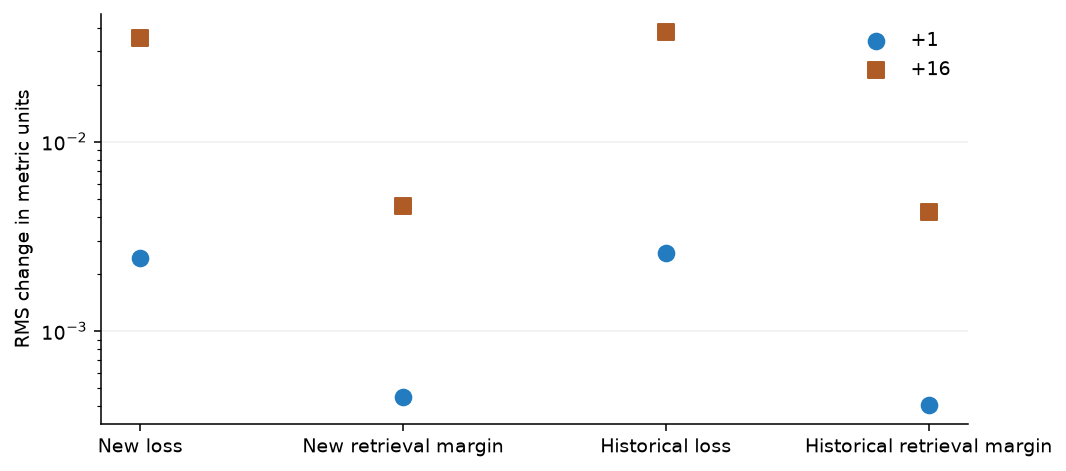

Component,+1 scale,+16 scale,+16 / +1,+1 weight,+16 weight
New loss,0.002418,0.035341,14.6×,40%,35%
New retrieval margin,0.000449,0.004571,10.2×,30%,30%
Historical loss,0.002572,0.037816,14.7×,10%,20%
Historical retrieval margin,0.000406,0.004250,10.5×,20%,15%


Horizon,Branch outcomes,Spectral penalty > 0,Conditional historical CKA penalty > 0
+1,1440,0,300
+16,1920,13,383


In [3]:
fixed_scales = np.array([calibration['scales'][str(h)] for h in (1, 16)])
for h, scales in zip((1, 16), fixed_scales):
    np.testing.assert_allclose(np.sqrt(np.mean(arrays[f'raw{h}']**2, axis=(0, 1, 2, 3))), scales)
weights = np.array([[.40, .30, .10, .20], [.35, .30, .20, .15]])
fig, ax = plt.subplots(figsize=(7.5, 3.25), layout='constrained')
for values, label, color, marker in zip(fixed_scales, ('+1', '+16'), ('#237cc0', '#ae5b25'), ('o', 's')):
    ax.scatter(np.arange(4), values, label=label, color=color, marker=marker, s=65, zorder=2)
ax.set(yscale='log', ylabel='RMS change in metric units', xticks=np.arange(4), xticklabels=metrics)
ax.grid(axis='y', which='major', alpha=.2)
ax.legend(frameon=False)
display(fig)
display(table(('Component', '+1 scale', '+16 scale', '+16 / +1', '+1 weight', '+16 weight'), [
    (label, f'{a:.6f}', f'{b:.6f}', f'{b/a:.1f}×', f'{w:.0%}', f'{v:.0%}')
    for label, a, b, w, v in zip(metrics, *fixed_scales, *weights)
]))
display(table(('Horizon', 'Branch outcomes', 'Spectral penalty > 0', 'Conditional historical CKA penalty > 0'), [
    (f'+{h}', int(np.prod(arrays[f'penalties{h}'].shape[:-1])),
     int(np.count_nonzero(arrays[f'penalties{h}'][..., 0])), int(np.count_nonzero(arrays[f'penalties{h}'][..., 1])))
    for h in (1, 16)
]))

## Development diagnostics · Can health identify a useful action?

At each checkpoint, one mask draw selects the action and the other scores it. The two directions are averaged. Both diagnostics compare with the development-selected fixed action. The semantic oracle uses downstream outcomes to select retrospectively. The health oracle uses each branch's realized unlabeled reward. It requires observing the action's outcome and is a diagnostic for objective alignment.

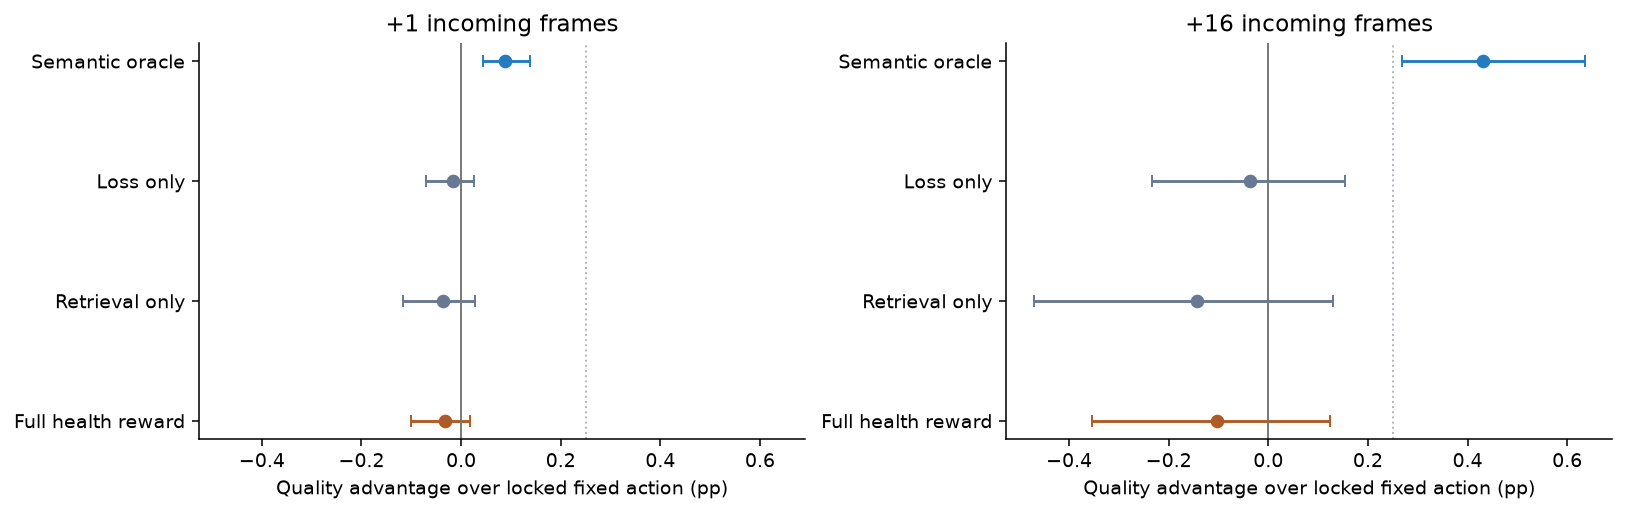

Horizon,Action selector,"Other-draw advantage (pp, 95% interval)",Action agreement across draws
+1,Semantic oracle,"+0.088 [+0.044, +0.138]",53.3%
+1,Loss only,"-0.016 [-0.070, +0.027]",96.7%
+1,Retrieval only,"-0.036 [-0.117, +0.027]",90.0%
+1,Full health reward,"-0.032 [-0.101, +0.018]",93.3%
+16,Semantic oracle,"+0.430 [+0.268, +0.635]",51.7%
+16,Loss only,"-0.037 [-0.233, +0.154]",77.5%
+16,Retrieval only,"-0.142 [-0.471, +0.129]",62.5%
+16,Full health reward,"-0.103 [-0.354, +0.125]",74.2%


In [4]:
def chosen(outcomes, action):
    return np.take_along_axis(outcomes, action[..., None], axis=-1).squeeze(-1)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.55), sharex=True, layout='constrained')
diagnostic = []
for h, ax in zip((1, 16), axes):
    q = arrays[f'quality{h}'][..., 0]
    r = arrays[f'reward{h}']
    fixed = q[..., calibration['fixed'][str(h)]]
    names = ('Semantic oracle', 'Loss only', 'Retrieval only', 'Full health reward')
    choices = (q.argmax(-1), r[..., 0].argmax(-1), r[..., 1].argmax(-1), r[..., -1].argmax(-1))
    for i, (name, choice) in enumerate(zip(names, choices)):
        value = chosen(q, choice[:, :, ::-1]) - fixed
        point, (lo, hi) = estimate(value)
        color = '#237cc0' if i == 0 else '#ae5b25' if i == 3 else '#697993'
        ax.errorbar(point, i, xerr=[[point-lo], [hi-point]], fmt='o', color=color, capsize=3)
        diagnostic.append((f'+{h}', name, interval(value), f'{np.mean(choice[:,:,0] == choice[:,:,1]):.1%}'))
    ax.axvline(0, color='#777', lw=1)
    ax.axvline(calibration['threshold_pp'], color='#b0b5bf', lw=1, linestyle=':')
    ax.set(yticks=np.arange(len(names)), yticklabels=names, title=f'+{h} incoming frames',
           xlabel='Quality advantage over locked fixed action (pp)')
    ax.invert_yaxis()
display(fig)
display(table(('Horizon', 'Action selector', 'Other-draw advantage (pp, 95% interval)', 'Action agreement across draws'), diagnostic))

## What Stage B tests

Stage B evaluates the frozen health scaling and fixed baselines on **40 different captures per seed**. A horizon opens the prospective controller test only if the semantic oracle and the full health reward each gain at least **+0.25 pp** over the fixed comparator, with positive 95% intervals in both same-draw and independent-draw comparisons. The development checks above use independent masks on the same development captures. Their intervals describe the development sample.

### Reproducibility

This notebook embeds the paired development measurements used in its figures. The original receipts also contain per-task probes, capture and checkpoint identities, replay image IDs, and full branch timings. The archived Phase 1.2.5 walk SHA-256 is `beb34e73894f72e7a59d578612b5ee045f3bc96effe3b549e341cf8c463b9cbb`. The development receipt archive SHA-256 is `dfef04d4f046d1f646d8311ae237e6a408a57174c627e47f9a35afecc81d75b0`.